# Vulkan VU: RAG vs model memory — report figures

Companion to `reports/report.md`. Final run = pilot (`runs/pilot`), exploratory analysis (PLAN §10, 2026-11-10). All numbers come from `vkrag.report`, the same code that writes `reports/report_tables.md`.

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from vkrag.config import ROOT
from vkrag import report

R = report.Run('pilot', 'pilot')
data = {'table1': report.table1(R), 'table2': report.table2(R), 'by_stratum': report.by_stratum(R),
        'table4': report.table4(R)}
paths = report.figures(data, ROOT / 'reports' / 'figures')
[p.name for p in paths]

['score_by_stratum.png',
 'recall_at_k.png',
 'pareto_cost_remote.png',
 'score_vs_latency.png']

## Generation: score by configuration (answerable questions, n = 45 per cell)

In [2]:
rows = []
for k, v in data['table2'].items():
    a, c = k.split('|')
    rows.append({'answerer': a, 'config': c, 'score': v['score'], 'ci_lo': v['score_ci']['ci95'][0],
                 'ci_hi': v['score_ci']['ci95'][1], 'correct': v['correct'], 'hallucination': v['hallucination'],
                 'fabricated_vuid': v['fabricated_vuid']})
pd.DataFrame(rows).pivot(index='config', columns='answerer', values='score').loc[list(report.GEN_CONFIGS)]

answerer,qwen,remote
config,,
closed,0.278,0.500
bm25,0.689,0.789
dense,0.767,0.733
rrf,0.767,0.822
rrf_rerank,0.700,0.844
rewrite_rrf_rerank,0.689,0.789
hyde_rrf_rerank,0.667,0.800
oracle,0.956,0.944
oracle_distract,0.922,0.967


## Score by stratum (H1)

n = 9 questions per bar; the intervals are wide and overlap, so the stratum pattern is descriptive only.

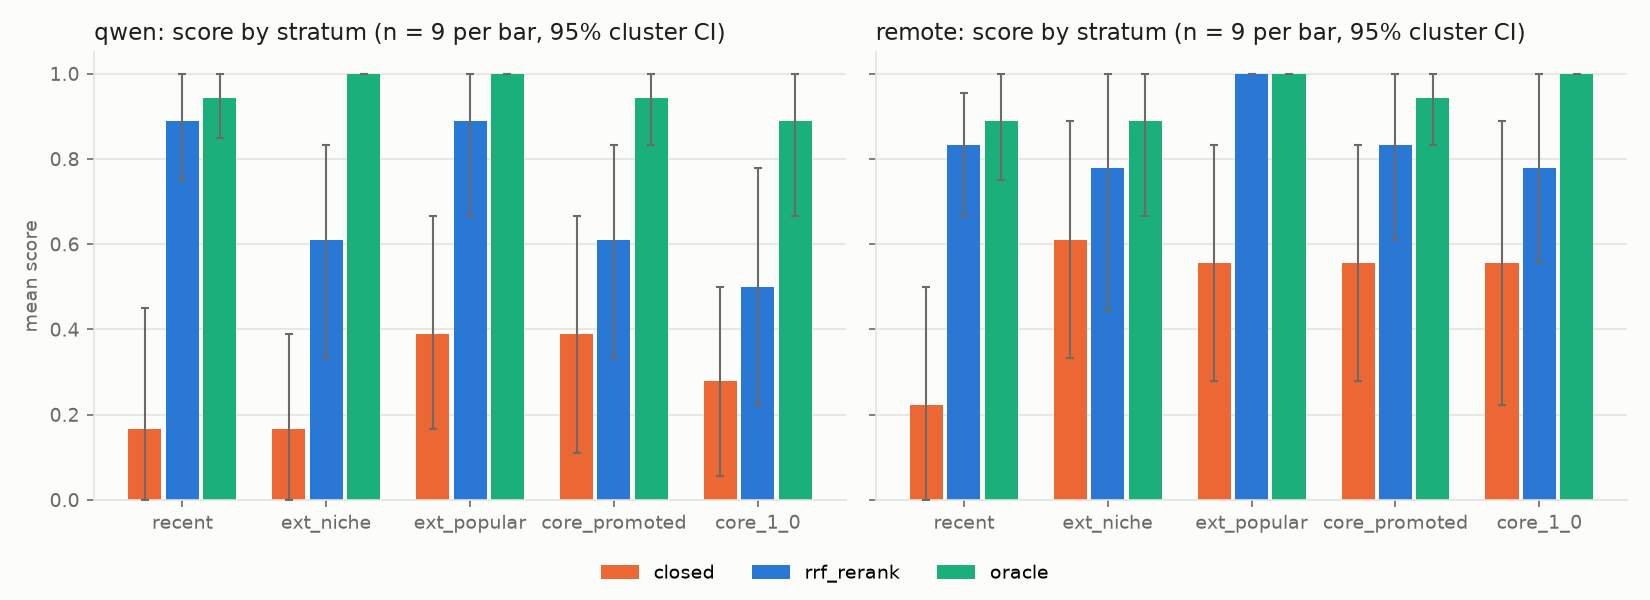

In [3]:
display(Image(filename=str(ROOT / 'reports/figures/score_by_stratum.png')))

## Retrieval: Recall@k by equivalence class (H2, H3a)

In [4]:
pd.DataFrame({c: {k: data['table1'][c]['all'][f'class@{k}'] for k in (1, 3, 5, 10, 20)}
              for c in ('bm25', 'dense', 'rrf', 'rrf_rerank', 'hyde_rrf', 'rewrite_rrf')}).T

,1,3,5,10,20
bm25,0.4333,0.6333,0.6889,0.7667,0.8111
dense,0.5000,0.6667,0.6889,0.7444,0.7778
rrf,0.4778,0.6778,0.7222,0.7556,0.8333
rrf_rerank,0.3000,0.4778,0.5333,0.6778,0.7444
hyde_rrf,0.5222,0.6556,0.7222,0.7667,0.8556
rewrite_rrf,0.3889,0.6222,0.6667,0.7556,0.8111


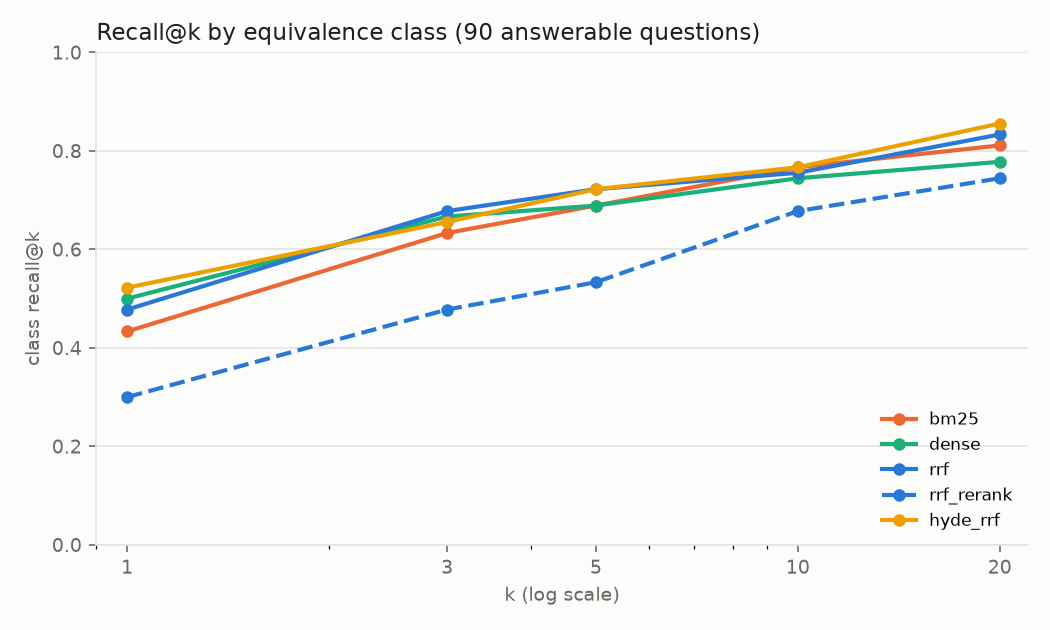

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/recall_at_k.png')))

## Cost (H5): remote answerer, score vs cost per question

In [6]:
pd.DataFrame(data['table4']['remote']).T[['score', 'cost_per_question', 'cost_per_correct', 'tokens_in_mean', 'tokens_out_mean']]

,score,cost_per_question,cost_per_correct,tokens_in_mean,tokens_out_mean
closed,0.500,0.000097,0.000195,114.0,291.0
bm25,0.789,0.000238,0.000301,1373.0,163.0
dense,0.733,0.000204,0.000278,1125.0,167.0
rrf,0.822,0.000216,0.000263,1220.0,165.0
rrf_rerank,0.844,0.000318,0.000376,1953.0,158.0
rewrite_rrf_rerank,0.789,0.000296,0.000375,1842.0,154.0
hyde_rrf_rerank,0.800,0.000290,0.000362,1993.0,161.0
oracle,0.944,0.000125,0.000133,680.0,107.0
oracle_distract,0.967,0.000189,0.000196,1129.0,111.0
rrf_rerank_strict,0.611,0.000296,0.000484,1935.0,88.0


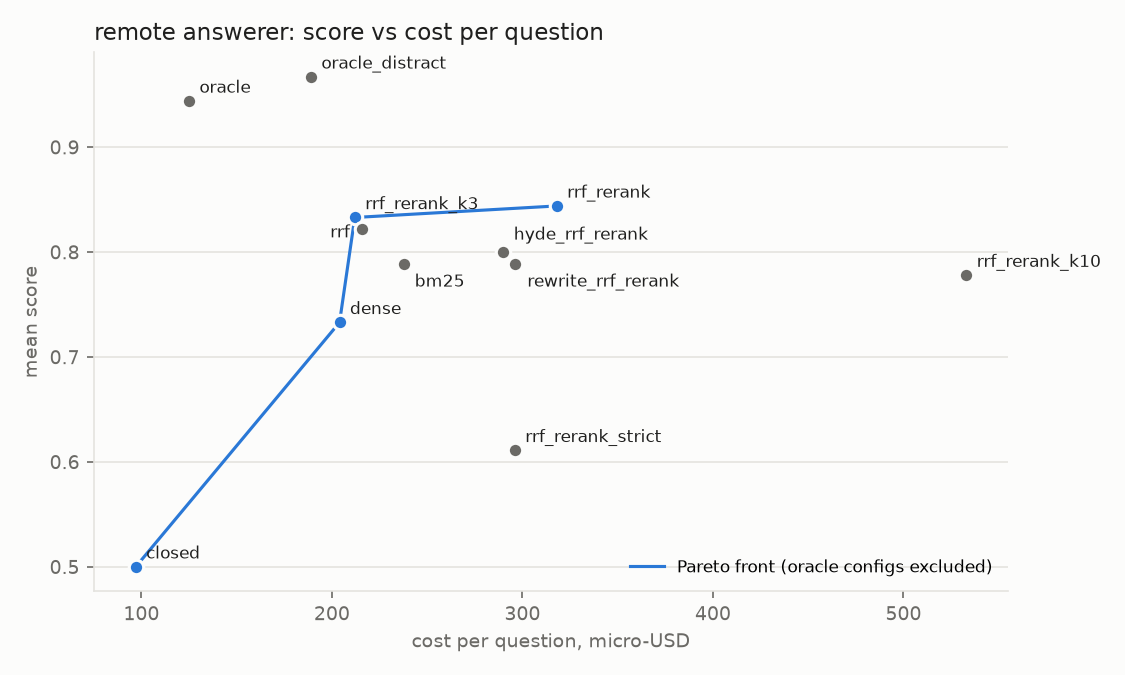

In [7]:
display(Image(filename=str(ROOT / 'reports/figures/pareto_cost_remote.png')))

## Score vs answer latency

Latency of the generation call only (no phase L, no retrieval time); qwen ran locally and sequentially, remote through OpenRouter.

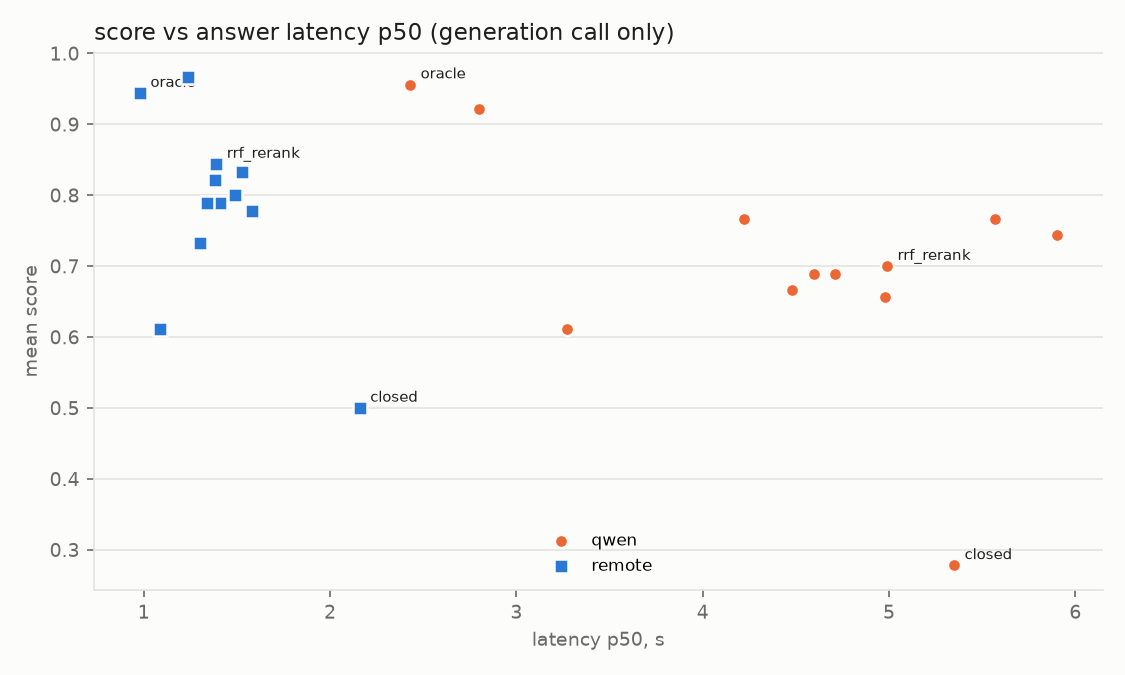

In [8]:
display(Image(filename=str(ROOT / 'reports/figures/score_vs_latency.png')))

## Hypothesis tests (exploratory)

In [9]:
h = json.loads((ROOT / 'runs/pilot/hypotheses.json').read_text(encoding='utf-8'))
pd.DataFrame({k: {f: v.get(f) for f in ('comparison', 'mean_a', 'mean_b', 'diff', 'ci95', 'p', 'p_holm')}
              for k, v in h['tests'].items()}).T

,comparison,mean_a,mean_b,diff,ci95,p,p_holm
H1a,qwen rrf_rerank vs closed,0.2778,0.7,0.4222,"[0.2766, 0.5581]",0.0001,0.0008
H1b,remote rrf_rerank vs closed,0.5,0.8444,0.3444,"[0.1977, 0.4792]",0.0003,0.0021
H2a,rrf vs bm25,0.6889,0.7222,0.0333,"[-0.0227, 0.0889]",0.45135,1.0
H2b,rrf vs dense,0.6889,0.7222,0.0333,"[-0.0114, 0.0814]",0.38276,1.0
H3a,rrf_rerank vs rrf,0.7222,0.5333,-0.1889,"[-0.29, -0.087]",0.0011,0.0066
H3b,"rrf_rerank vs rrf, both answerers",0.7944,0.7722,-0.0222,"[-0.1277, 0.0795]",0.75672,1.0
H4,qwen rrf_rerank - remote closed (non-inferiority),0.5,0.7,0.2,"[0.0227, 0.3723]",0.0032,0.0128
H5,remote rrf_rerank vs closed (cost),None,None,None,None,0.0013,0.0066
